In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, precision_recall_curve,
)

DATA_PATH = "/content/transactions.csv"
TIME_COL, LABEL_COL, GROUP_COL = "unix_time", "is_fraud", "ssn"
TEST_SIZE = 0.2
SEED = 42

In [ ]:
import os
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"No file Loaded"
    )

df = pd.read_csv(DATA_PATH, sep="|")
y_all = df[LABEL_COL].to_numpy()
print(f"{len(df):,} rows | {y_all.sum():,} fraud ({y_all.mean():.3%} base rate)")
df.head()

75,699 rows | 509 fraud (0.672% base rate)


,ssn,cc_num,first,last,gender,street,city,state,zip,lat,...,unix_time,category,amt,is_fraud,merchant,merch_lat,merch_long,mcc,merchant_size,transaction_velocity
0,082-30-1655,5332871012269166,Matthew,Mejia,M,7525 Clark Grove Apt. 928,Newport News,VA,23603,37.1989,...,1767410496,food_dining,6.82,0,Tim Hortons,37.575449,-76.373831,5812,large,0
1,082-30-1655,5332871012269166,Matthew,Mejia,M,7525 Clark Grove Apt. 928,Newport News,VA,23603,37.1989,...,1767713648,food_dining,74.95,0,Burger King,37.889978,-76.849635,5812,medium,0
2,082-30-1655,5332871012269166,Matthew,Mejia,M,7525 Clark Grove Apt. 928,Newport News,VA,23603,37.1989,...,1767796570,food_dining,1.36,0,Sonic Drive-In,37.320966,-75.774449,5812,large,1
3,082-30-1655,5332871012269166,Matthew,Mejia,M,7525 Clark Grove Apt. 928,Newport News,VA,23603,37.1989,...,1767909687,food_dining,94.96,0,Tim Hortons,36.201250,-77.134257,5812,large,0
4,082-30-1655,5332871012269166,Matthew,Mejia,M,7525 Clark Grove Apt. 928,Newport News,VA,23603,37.1989,...,1767980399,food_dining,389.97,0,Shake Shack,36.514838,-76.829420,5812,medium,1


In [ ]:
def haversine_miles(lat1, lon1, lat2, lon2):
    r = 3958.8
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

RAW_COLS = [
    "unix_time", "transaction_velocity", "amt", "mcc",
    "lat", "long", "merch_lat", "merch_long",
]
CALCULATED_COLS = [
    "distance_from_home", "distance_from_last_txn",
    "repeat_retailer", "txn_during_night", "trans_weekend",
]

# FEATURE_COLS = RAW_COLS                    # raw attributes only
FEATURE_COLS = RAW_COLS + CALCULATED_COLS    # raw + calculated attributes

def engineer(df):
    ordered = df.sort_values([GROUP_COL, TIME_COL])
    prev_lat = ordered.groupby(GROUP_COL)["merch_lat"].shift()
    prev_long = ordered.groupby(GROUP_COL)["merch_long"].shift()
    dist_last = haversine_miles(prev_lat, prev_long, ordered["merch_lat"], ordered["merch_long"]).fillna(0)
    repeat = (ordered.groupby([GROUP_COL, "merchant"]).cumcount() > 0).astype(int)

    ts = pd.to_datetime(df[TIME_COL], unit="s", errors="coerce")

    out = df[RAW_COLS].copy()
    out["distance_from_home"] = haversine_miles(df["lat"], df["long"], df["merch_lat"], df["merch_long"])
    out["distance_from_last_txn"] = dist_last.reindex(df.index)
    out["repeat_retailer"] = repeat.reindex(df.index)
    out["txn_during_night"] = ((ts.dt.hour >= 22) | (ts.dt.hour < 6)).astype(int)
    out["trans_weekend"] = ts.dt.dayofweek.isin([5, 6]).astype(int)

    return out[FEATURE_COLS]

X_all = engineer(df)
print("features:", list(X_all.columns))
X_all.head()

features: ['unix_time', 'transaction_velocity', 'amt', 'mcc', 'lat', 'long', 'merch_lat', 'merch_long', 'distance_from_home', 'distance_from_last_txn', 'repeat_retailer', 'txn_during_night', 'trans_weekend']


,unix_time,transaction_velocity,amt,mcc,lat,long,merch_lat,merch_long,distance_from_home,distance_from_last_txn,repeat_retailer,txn_during_night,trans_weekend
0,1767410496,0,6.82,5812,37.1989,-76.5821,37.575449,-76.373831,28.418812,0.000000,0,1,1
1,1767713648,0,74.95,5812,37.1989,-76.5821,37.889978,-76.849635,49.948082,33.886391,0,0,0
2,1767796570,1,1.36,5812,37.1989,-76.5821,37.320966,-75.774449,45.207716,70.777000,0,0,0
3,1767909687,0,94.96,5812,37.1989,-76.5821,36.201250,-77.134257,75.413285,107.937744,1,1,0
4,1767980399,1,389.97,5812,37.1989,-76.5821,36.514838,-76.829420,49.202559,27.516822,0,0,0


In [ ]:
Xtr, Xte, ytr, yte = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED
)

print(f"train {len(Xtr):,} rows ({ytr.mean():.3%} fraud) | test {len(Xte):,} rows ({yte.mean():.3%} fraud)")

results = []

train 60,559 rows (0.672% fraud) | test 15,140 rows (0.674% fraud)


In [ ]:
NUMERIC_COLS = [c for c in X_all.columns if pd.api.types.is_numeric_dtype(X_all[c])]
CATEGORICAL_COLS = [c for c in X_all.columns if c not in NUMERIC_COLS]

def build_preprocessor(scale):
    numeric = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", numeric, NUMERIC_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
    ])

def evaluate(name, y_true, y_prob):
    prec, rec, thresh = precision_recall_curve(y_true, y_prob)
    f1 = np.where((prec + rec) > 0, 2 * prec * rec / (prec + rec + 1e-12), 0)
    best_i = f1.argmax()
    y_pred_05 = (y_prob >= 0.5).astype(int)
    return {
        "model": name,
        "precision@0.5": precision_score(y_true, y_pred_05, zero_division=0),
        "recall@0.5": recall_score(y_true, y_pred_05, zero_division=0),
        "f1@0.5": f1_score(y_true, y_pred_05, zero_division=0),
        "best_precision": prec[best_i],
        "best_recall": rec[best_i],
        "best_f1": f1[best_i],
        "AUPRC": average_precision_score(y_true, y_prob),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
    }

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV

CV_FOLDS = 4
groups_tr = df.loc[Xtr.index, GROUP_COL].to_numpy()
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
SCORING = "average_precision"

def run_grid_search(name, estimator, param_grid, scale, sampler=None):
    steps = [("pre", build_preprocessor(scale=scale))]
    if sampler is not None:
        from imblearn.pipeline import Pipeline as PipelineCls
        steps.append(("smp", sampler))
    else:
        PipelineCls = Pipeline
    steps.append(("clf", estimator))

    search = GridSearchCV(
        PipelineCls(steps), param_grid, scoring=SCORING, cv=cv,
        n_jobs=-1, refit=True, verbose=1,
    )
    search.fit(Xtr, ytr, groups=groups_tr)

    print(f"{name}: best CV {SCORING} = {search.best_score_:.4f}")
    print("best params:", search.best_params_)

    res = evaluate(name, yte, search.predict_proba(Xte)[:, 1])
    results[:] = [r for r in results if r["model"] != name] + [res]
    return search, res

1. Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_search, lr_result = run_grid_search(
    "LogisticRegression",
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    {
        "clf__C": [0.01, 0.1, 1.0, 10.0],
    },
    scale=True,
)
lr_result

Fitting 4 folds for each of 4 candidates, totalling 16 fits
LogisticRegression: best CV average_precision = 0.0452
best params: {'clf__C': 0.01}


{'model': 'LogisticRegression',
 'precision@0.5': 0.011440360090022505,
 'recall@0.5': 0.5980392156862745,
 'f1@0.5': 0.022451232977548766,
 'best_precision': np.float64(0.06976744186046512),
 'best_recall': np.float64(0.11764705882352941),
 'best_f1': np.float64(0.08759124087544505),
 'AUPRC': np.float64(0.02654414319911256),
 'ROC_AUC': np.float64(0.673965170587453)}

2. Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_search, dt_result = run_grid_search(
    "DecisionTree",
    DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    {
        "clf__max_depth": [6, 8, 12, None],
        "clf__min_samples_leaf": [10, 20, 50],
    },
    scale=False,
)
dt_result

Fitting 4 folds for each of 12 candidates, totalling 48 fits
DecisionTree: best CV average_precision = 0.3236
best params: {'clf__max_depth': 12, 'clf__min_samples_leaf': 10}


{'model': 'DecisionTree',
 'precision@0.5': 0.059534883720930236,
 'recall@0.5': 0.6274509803921569,
 'f1@0.5': 0.10875106202209006,
 'best_precision': np.float64(0.88),
 'best_recall': np.float64(0.43137254901960786),
 'best_f1': np.float64(0.5789473684206111),
 'AUPRC': np.float64(0.49495949932507655),
 'ROC_AUC': np.float64(0.8223464608612431)}

3. Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_search, rf_result = run_grid_search(
    "RandomForest",
    RandomForestClassifier(
        class_weight="balanced_subsample", n_jobs=1, random_state=SEED,
    ),
    {
        "clf__n_estimators": [200, 400],
        "clf__max_depth": [10, 16, None],
        "clf__min_samples_leaf": [2, 5, 10],
    },
    scale=False,
)
rf_result

Fitting 4 folds for each of 18 candidates, totalling 72 fits
RandomForest: best CV average_precision = 0.1825
best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}


{'model': 'RandomForest',
 'precision@0.5': 1.0,
 'recall@0.5': 0.20588235294117646,
 'f1@0.5': 0.34146341463414637,
 'best_precision': np.float64(0.8333333333333334),
 'best_recall': np.float64(0.6862745098039216),
 'best_f1': np.float64(0.7526881720425155),
 'AUPRC': np.float64(0.795629943856064),
 'ROC_AUC': np.float64(0.9950002477384091)}

4. XGBoost

In [ ]:
from xgboost import XGBClassifier

pos_w = (len(ytr) - ytr.sum()) / max(ytr.sum(), 1)

xgb_search, xgb_result = run_grid_search(
    "XGBoost",
    XGBClassifier(
        scale_pos_weight=pos_w, eval_metric="aucpr", tree_method="hist",
        n_jobs=1, random_state=SEED,
    ),
    {
        "clf__n_estimators": [300, 600],
        "clf__max_depth": [4, 6, 8],
        "clf__learning_rate": [0.03, 0.1],
        "clf__subsample": [0.9],
        "clf__colsample_bytree": [0.9],
    },
    scale=False,
)
xgb_result

Fitting 4 folds for each of 12 candidates, totalling 48 fits
XGBoost: best CV average_precision = 0.3649
best params: {'clf__colsample_bytree': 0.9, 'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 600, 'clf__subsample': 0.9}


{'model': 'XGBoost',
 'precision@0.5': 1.0,
 'recall@0.5': 0.7647058823529411,
 'f1@0.5': 0.8666666666666667,
 'best_precision': np.float64(0.9761904761904762),
 'best_recall': np.float64(0.803921568627451),
 'best_f1': np.float64(0.8817204301070316),
 'AUPRC': np.float64(0.9337971262416503),
 'ROC_AUC': np.float64(0.9991928943408724)}

5. Neural Network

In [ ]:
from sklearn.neural_network import MLPClassifier
from imblearn.over_sampling import RandomOverSampler


nn_search, nn_result = run_grid_search(
    "NeuralNetwork",
    MLPClassifier(
        activation="relu", batch_size=512, learning_rate_init=1e-3,
        max_iter=60, early_stopping=True, n_iter_no_change=8, random_state=SEED,
    ),
    {
        "clf__hidden_layer_sizes": [(64,), (128, 64)],
        "clf__alpha": [1e-4, 1e-3],
    },
    scale=True,
    sampler=RandomOverSampler(sampling_strategy=0.1, random_state=SEED),
)
nn_result

Fitting 4 folds for each of 4 candidates, totalling 16 fits
NeuralNetwork: best CV average_precision = 0.2694
best params: {'clf__alpha': 0.001, 'clf__hidden_layer_sizes': (64,)}


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


{'model': 'NeuralNetwork',
 'precision@0.5': 0.5425531914893617,
 'recall@0.5': 0.5,
 'f1@0.5': 0.5204081632653061,
 'best_precision': np.float64(0.7704918032786885),
 'best_recall': np.float64(0.46078431372549017),
 'best_f1': np.float64(0.5766871165639488),
 'AUPRC': np.float64(0.5344891271906803),
 'ROC_AUC': np.float64(0.9158139249848097)}

Results

In [ ]:
order = ["LogisticRegression", "DecisionTree", "RandomForest", "XGBoost", "NeuralNetwork"]
results_df = pd.DataFrame(results).set_index("model")
results_df = results_df.loc[[m for m in order if m in results_df.index]]
results_df

,precision@0.5,recall@0.5,f1@0.5,best_precision,best_recall,best_f1,AUPRC,ROC_AUC
model,,,,,,,,
LogisticRegression,0.011440,0.598039,0.022451,0.069767,0.117647,0.087591,0.026544,0.673965
DecisionTree,0.059535,0.627451,0.108751,0.880000,0.431373,0.578947,0.494959,0.822346
RandomForest,1.000000,0.205882,0.341463,0.833333,0.686275,0.752688,0.795630,0.995000
XGBoost,1.000000,0.764706,0.866667,0.976190,0.803922,0.881720,0.933797,0.999193
NeuralNetwork,0.542553,0.500000,0.520408,0.770492,0.460784,0.576687,0.534489,0.915814


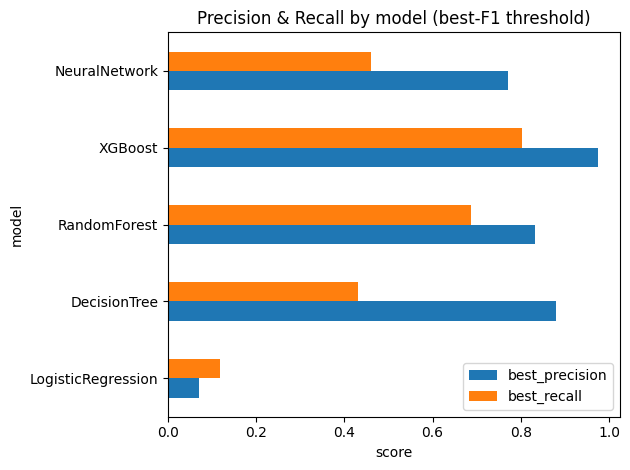

In [ ]:
results_df[["best_precision", "best_recall"]].plot.barh(title="Precision & Recall by model (best-F1 threshold)")
plt.xlabel("score")
plt.tight_layout()